In [73]:
import numpy as np #导入程序所需的包
import sklearn
from matplotlib import colors     
from sklearn import svm            
from sklearn.svm import SVC
from sklearn import model_selection
import matplotlib.pyplot as plt
import matplotlib as mpl

In [74]:
def iris_type(s):
    it = {b'Iris-setosa':0, b'Iris-versicolor':1, b'Iris-virginica':2}
    return it[s]

In [75]:
data_path='iris.data'

In [76]:
data = np.loadtxt(data_path,                                
                  dtype=float,                              
                  delimiter=',',                            
                  converters={4:iris_type}) 

In [77]:
x, y = np.split(data,                                      
                (4,),                                       
                axis=1)      

In [78]:
#print(x)
#print(y)

In [79]:
x = x[:, [0,2]]  #0:2 代表花萼长度，花萼宽度，进行数据训练，修改为 1:3 变为花萼宽度，花瓣长度进行训练最终图片是不一样的                                           
#print(x)
x_train,x_test,y_train,y_test=model_selection.train_test_split(x,              
                                                               y,             
                                                               random_state=1, 
                                                               test_size=0.2)  #修改test_size 可对最终图片结果造成影响

In [80]:
#print(x_train)

In [81]:
#print(y_train)

In [82]:
def classifier():
    clf = svm.SVC(C=10,                         
                  kernel='linear',               
                  decision_function_shape='ovr')
    # clf = sklearn.linear_model.LogisticRegression(multi_class='auto', solver = 'lbfgs')
    return clf

In [83]:
clf = classifier()

In [84]:
def train(clf,x_train,y_train):
    clf.fit(x_train,         
            y_train.ravel()) 

In [85]:
train(clf,x_train,y_train)

In [86]:
def show_accuracy(a, b, tip):
    acc = a.ravel() == b.ravel()
    print('%s Accuracy:%.3f' %(tip, np.mean(acc)))

In [87]:
def print_accuracy(clf,x_train,y_train,x_test,y_test):
    print('trianing prediction:%.3f' %(clf.score(x_train, y_train)))
    print('test data prediction:%.3f' %(clf.score(x_test, y_test)))
    show_accuracy(clf.predict(x_train), y_train, 'traing data')
    show_accuracy(clf.predict(x_test), y_test, 'testing data')
    print('decision_function:\n', clf.decision_function(x_train))

In [88]:
print_accuracy(clf,x_train,y_train,x_test,y_test)

trianing prediction:0.967
test data prediction:1.000
traing data Accuracy:0.967
testing data Accuracy:1.000
decision_function:
 [[-0.26773983  2.2662589   1.03362722]
 [-0.2944635   1.19803723  2.28646353]
 [-0.2376491   2.28326346  0.74653219]
 [-0.28773706  1.13585214  2.28300074]
 [-0.27901968  1.19346064  2.26321802]
 [ 2.24584967  1.31171077 -0.31504467]
 [-0.24298725  2.27829159  0.76568166]
 [ 2.25087168  1.31196179 -0.31545002]
 [-0.26840961  2.27596273  0.86555928]
 [-0.29053102  1.11630989  2.28736779]
 [-0.28667429  1.21916667  2.26952912]
 [ 2.25113819  1.31166991 -0.31525895]
 [-0.27725875  1.22899114  2.24444082]
 [-0.28765517  1.10776994  2.28445498]
 [-0.26857492  2.27796529  0.84463589]
 [-0.301056    0.79170003  2.30553962]
 [ 2.23292949  1.31179203 -0.3146005 ]
 [ 2.25140298  1.31136995 -0.31506376]
 [ 2.25192747  1.3107444  -0.31466045]
 [-0.23618715  2.27602796  0.76512475]
 [ 2.24644741  1.31110475 -0.31464051]
 [ 2.25438004  1.31327561 -0.31653277]
 [-0.2996268  

In [89]:
def draw(clf, x):
    iris_feature = 'sepal length', 'sepal width', 'petal lenght', 'petal width'
    # 开始画图,上面英文为花萼长度，花萼宽度，花瓣长度，花瓣宽度
    x1_min, x1_max = x[:, 0].min(), x[:, 0].max()               
    x2_min, x2_max = x[:, 1].min(), x[:, 1].max()               
    x1, x2 = np.mgrid[x1_min:x1_max:200j, x2_min:x2_max:200j]   
    grid_test = np.stack((x1.flat, x2.flat), axis=1)            
    print('grid_test:\n', grid_test)
    # 输出样本到决策面的距离
    z = clf.decision_function(grid_test)
    print('the distance to decision plane:\n', z)
    
    grid_hat = clf.predict(grid_test)                          
    print('grid_hat:\n', grid_hat)  
    grid_hat = grid_hat.reshape(x1.shape)                       
                                                                 
 
    cm_light = mpl.colors.ListedColormap(['#A0FFA0', '#FFA0A0', '#A0A0FF'])
    cm_dark = mpl.colors.ListedColormap(['g', 'b', 'r'])
 
    plt.pcolormesh(x1, x2, grid_hat, cmap=cm_light,shading='auto')                                   
                                                                                      
    plt.scatter(x[:, 0], x[:, 1], c=np.squeeze(y), edgecolor='k', s=50, cmap=cm_dark) 
    plt.scatter(x_test[:, 0], x_test[:, 1], s=120, facecolor='none', zorder=10)      
    plt.xlabel(iris_feature[0], fontsize=20)
    plt.ylabel(iris_feature[1], fontsize=20)
    plt.xlim(x1_min, x1_max)
    plt.ylim(x2_min, x2_max)
    plt.title('svm in iris data classification', fontsize=30)
    plt.grid()
    plt.show()

grid_test:
 [[4.3        1.        ]
 [4.3        1.02964824]
 [4.3        1.05929648]
 ...
 [7.9        6.84070352]
 [7.9        6.87035176]
 [7.9        6.9       ]]
the distance to decision plane:
 [[ 2.26714334  1.31150492 -0.3160681 ]
 [ 2.26627903  1.31133786 -0.3159048 ]
 [ 2.26539185  1.31116821 -0.31573838]
 ...
 [-0.30072888  0.8321999   2.30367007]
 [-0.30093459  0.8231846   2.30414003]
 [-0.30113772  0.81510056  2.30459533]]
grid_hat:
 [0. 0. 0. ... 2. 2. 2.]


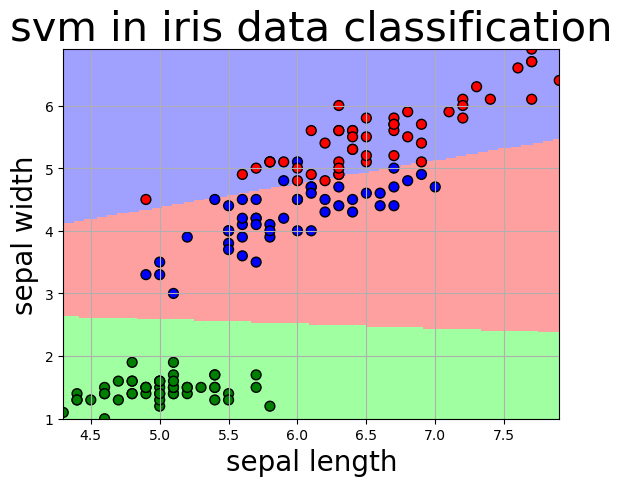

In [90]:
draw(clf,x)